# 11 - Derivação numérica
Vamos aprender sobre como usar técnicas para calcular a derivada de uma função matemática por meio do método das diferenças finitas, usando o limite do valor do quociente das diferenças quando a reta secante se aproxima da reta tangente.

Crie uma nova branch (versão) do repositório:

```bash
git branch semana11
```

Faça o checkout nessa nova branch:

```bash
git checkout semana11
```

<hr />

## Atividade 1
Escreva o método das diferenças finitas dentro do arquivo $utils/algoritmos.py$.

In [4]:
def dp(f, x, h):
    return (f(x + h) - f(x)) / h


def dr(f, x, h):
    return (f(x) - f(x - h)) / h


def dc(f, x, h):
    return (f(x + h) - f(x - h)) / (2 * h)

Use os esquemas numéricos de **diferença finita regressiva de ordem 1**, **diferença finita progressiva de ordem 1** e **diferença finita central de ordem 2** para aproximar as seguintes derivadas:

- $f'(x)$ onde $f(x) = \sin(x)$ e $x = 2$  
- $f'(x)$ onde $f(x) = e^{-x}$ e $x = 1$

Use $h = 10^{-2}$ e $h = 10^{-3}$ e compare com os valores obtidos pela derivada exata.

**Respostas esperadas:**

- Para $f'(x)$ onde $f(x) = \sin(x)$ e $x = 2$:

  - Progressiva (ordem 1): $-0.42069$ e $-0.41660$
  - Regressiva (ordem 1): $-0.41159$ e $-0.41569$
  - Central (ordem 2): $-0.41614$ e $-0.41615$
  - Exata: $\cos(2) = -0.41615$

- Para $f'(x)$ onde $f(x) = e^{-x}$ e $x = 1$:

  - Progressiva (ordem 1): $-0.36605$ e $-0.36788$
  - Regressiva (ordem 1): $-0.36972$ e $-0.36806$
  - Central (ordem 2): $-0.36789$ e $-0.36788$
  - Exata: $-e^{-1} = -0.36788$

In [5]:
import sys
import os
import numpy as np

sys.path.append(os.path.abspath(os.path.join('..')))

from utils.algoritmos import dp, dr, dc


def main():
    h_values = [1e-2, 1e-3]

    print('f(x) = sin(x), x = 2')
    f = lambda x: np.sin(x)
    for h in h_values:
        print(f'h = {h}: progressiva = {dp(f, 2, h):.8f}, regressiva = {dr(f, 2, h):.8f}, central = {dc(f, 2, h):.8f}')
    print(f'exata = {np.cos(2):.8f}')

    print('\nf(x) = exp(-x), x = 1')
    f = lambda x: np.exp(-x)
    for h in h_values:
        print(f'h = {h}: progressiva = {dp(f, 1, h):.8f}, regressiva = {dr(f, 1, h):.8f}, central = {dc(f, 1, h):.8f}')
    print(f'exata = {-np.exp(-1):.8f}')


if __name__ == "__main__":
    main()

f(x) = sin(x), x = 2
h = 0.01: progressiva = -0.42068635, regressiva = -0.41159345, central = -0.41613990
h = 0.001: progressiva = -0.41660142, regressiva = -0.41569212, central = -0.41614677
exata = -0.41614684

f(x) = exp(-x), x = 1
h = 0.01: progressiva = -0.36604616, regressiva = -0.36972499, central = -0.36788557
h = 0.001: progressiva = -0.36769556, regressiva = -0.36806344, central = -0.36787950
exata = -0.36787944


## Atividade 2
As tensões na entrada $v_i$ e saída $v_o$ de um amplificador foram medidas em regime estacionário conforme a tabela abaixo:

| $v_i$ (V) | 0.0 | 0.5 | 1.0 | 1.5 | 2.0 | 2.5 | 3.0 | 3.5 | 4.0 | 4.5 | 5.0 |
|:----------:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| $v_o$ (V) | 0.0 | 1.05 | 1.83 | 2.69 | 3.83 | 4.56 | 5.49 | 6.56 | 6.11 | 7.06 | 8.29 |

O ganho é definido por:

$$
G = \frac{\partial v_o}{\partial v_i}
$$

Calcule o ganho quando $v_i = 1$ e $v_i = 4.5$ usando as seguintes técnicas:

a. Derivada primeira numérica de **primeira ordem** usando o próprio ponto e o **próximo**.  
b. Derivada primeira numérica de **primeira ordem** usando o próprio ponto e o **anterior**.  
c. Derivada primeira numérica de **segunda ordem** usando o ponto **anterior e o próximo**.  
d. Derivada primeira analítica da função do tipo  
   $v_o = a_1 v_i + a_3 v_i^3$  
   ajustada aos pontos pelo critério dos **mínimos quadrados**.

**Respostas esperadas:**

| Caso | a | b | c | d |
|:-----|:--:|:--:|:--:|:--:|
| $v_i = 1$ | 1.72 | 1.56 | 1.64 | 1.86 |
| $v_i = 4.5$ | 2.46 | 1.90 | 2.18 | 1.14 |

a1 = 1.89398693
a3 = -0.01247779
Modelo: vo = a1*vi + a3*vi^3
vi = 1.0: a=1.72000000, b=1.56000000, c=1.64000000, d=1.85655356
vi = 4.5: a=2.46000000, b=1.90000000, c=2.18000000, d=1.13596114


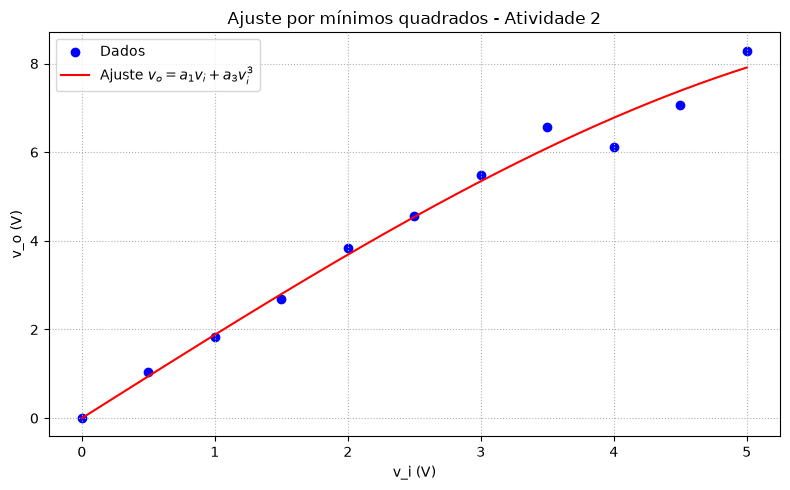

In [6]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join('..')))
from utils.algoritmos import regressao

vi = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0], dtype=float)
vo = np.array([0.0, 1.05, 1.83, 2.69, 3.83, 4.56, 5.49, 6.56, 6.11, 7.06, 8.29], dtype=float)

coef = regressao(vi, vo, lambda x: np.column_stack((x, x**3)))
a1, a3 = coef
print(f'a1 = {a1:.8f}')
print(f'a3 = {a3:.8f}')
print('Modelo: vo = a1*vi + a3*vi^3')

for x0 in [1.0, 4.5]:
    i = int(np.where(vi == x0)[0][0])
    a = (vo[i + 1] - vo[i]) / (vi[i + 1] - vi[i])
    b = (vo[i] - vo[i - 1]) / (vi[i] - vi[i - 1])
    c = (vo[i + 1] - vo[i - 1]) / (vi[i + 1] - vi[i - 1])
    d = a1 + 3 * a3 * x0**2
    print(f'vi = {x0}: a={a:.8f}, b={b:.8f}, c={c:.8f}, d={d:.8f}')

x_vals = np.linspace(vi.min(), vi.max(), 400)
y_fit = a1 * x_vals + a3 * x_vals**3

plt.figure(figsize=(8, 5))
plt.scatter(vi, vo, color='blue', label='Dados')
plt.plot(x_vals, y_fit, color='red', label='Ajuste $v_o = a_1 v_i + a_3 v_i^3$')
plt.xlabel('v_i (V)')
plt.ylabel('v_o (V)')
plt.title('Ajuste por mínimos quadrados - Atividade 2')
plt.grid(True, linestyle=':')
plt.legend()
plt.tight_layout()
plt.show()

## Versionando o código

Submeta a branch para o servidor:

```bash
git add .
git commit -m "Semana 11"
git push origin semana11
```